# Campus Recruitment: Predicting Student Placement

The goal is to predict whether an MBA student gets **placed** in a job, using their academic record, background and work experience. We explore the data, then train an **XGBoost** classifier and tune its decision threshold.

## 1. Import Libraries
We load the libraries used in this notebook:
- **pandas / numpy** for working with data
- **matplotlib / seaborn** for charts
- **kagglehub / os** to download and find the dataset
- **scikit-learn** for splitting, preprocessing and metrics
- **xgboost** for the classification model

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import xgboost as xgb
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score

## 2. Load the Dataset
We download the *Factors Affecting Campus Placement* dataset from Kaggle, read the CSV into a DataFrame and look at the first rows.

In [ ]:
path = kagglehub.dataset_download("benroshan/factors-affecting-campus-placement")
print("Path to dataset files:", path)

csv_path = os.path.join(path, "Placement_Data_Full_Class.csv")

df = pd.read_csv(csv_path)
df.head()

100%|██████████| 4.51k/4.51k [00:00<00:00, 11.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/benroshan/factors-affecting-campus-placement/versions/1


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


## 3. Data Overview
`df.info()` shows each column's data type and its non-null count. The dataset has **215 rows and 15 columns**, a mix of numeric (percentages) and categorical (text) features.

In [ ]:
# Check data types and structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    object 
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    object 
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    object 
 6   hsc_s           215 non-null    object 
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    object 
 9   workex          215 non-null    object 
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    object 
 12  mba_p           215 non-null    float64
 13  status          215 non-null    object 
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), object(8)
memory usage: 25.3+ KB


## 4. Prepare the Target and Drop Unneeded Columns
- Convert `status` to numbers: **Placed = 1**, **Not Placed = 0**.
- Drop `sl_no`, which is only a row ID.
- Drop `salary`, which is only known for students who were placed. Keeping it would leak the answer into the model.

In [ ]:
# First, let's convert the target variable to numeric
# status: Placed = 1, Not Placed = 0
df['status'] = df['status'].map({'Placed': 1, 'Not Placed': 0})

# Drop unnecessary columns
df = df.drop(['salary', 'sl_no'], axis=1)
df.head()

,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status
0,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,1
1,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,1
2,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,1
3,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,0
4,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,1


## 5. Check Target Balance
We check how the two classes are distributed. About **69% of students are placed** and **31% are not**, so the data is imbalanced. Accuracy alone can be misleading here, so we will also look at per-class metrics.

Target Distribution:
status
1    68.837209
0    31.162791
Name: proportion, dtype: float64


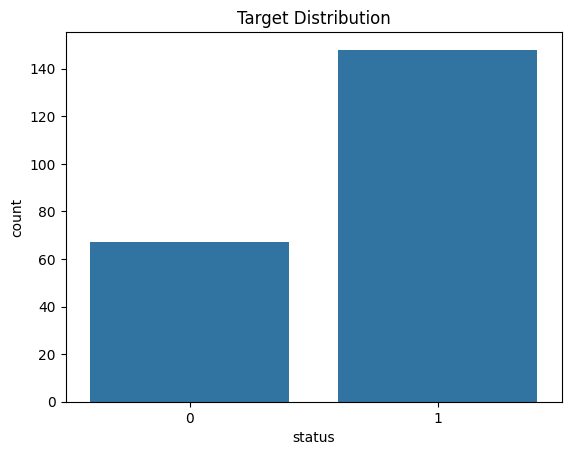

In [ ]:
def check_target_imbalance(df, target_column):
  print("Target Distribution:")
  print(f"{df[target_column].value_counts(normalize=True) * 100}" )
  sns.countplot(x=df[target_column])
  plt.title("Target Distribution")
  plt.show()

check_target_imbalance(df, "status")





## 6. Descriptive Statistics
Summary statistics (mean, standard deviation, min, max, quartiles) for the numeric columns. They show the range and spread of each score.

In [ ]:
# Descriptive statistics for numerical columns
df.describe()

,ssc_p,hsc_p,degree_p,etest_p,mba_p,status
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000
mean,67.303395,66.333163,66.370186,72.100558,62.278186,0.688372
std,10.827205,10.897509,7.358743,13.275956,5.833385,0.464240
min,40.890000,37.000000,50.000000,50.000000,51.210000,0.000000
25%,60.600000,60.900000,61.000000,60.000000,57.945000,0.000000
50%,67.000000,65.000000,66.000000,71.000000,62.000000,1.000000
75%,75.700000,73.000000,72.000000,83.500000,66.255000,1.000000
max,89.400000,97.700000,91.000000,98.000000,77.890000,1.000000


## 7. Missing Values
We work out the percentage of missing values in each column. The result is empty, so **there are no missing values** once `salary` is dropped.

In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_data = pd.DataFrame({
    'Column': missing_percentage.index,
    'Missing_Percentage': missing_percentage.values
})
missing_data = missing_data[missing_data['Missing_Percentage'] > 0].sort_values('Missing_Percentage', ascending=False)

print("Missing Data Analysis:")
missing_data

Missing Data Analysis:


,Column,Missing_Percentage


## 8. Duplicate Rows
We count duplicate rows and drop any we find. **No duplicates** were found.

In [ ]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(f"Number of Duplicate Samples: {duplicates}")
  if duplicates > 0:
    print("Dropping Duplicates...")
    df.drop_duplicates(inplace=True)
    print("Duplicates Dropped.")
  else:
    print("No Duplicate Samples Found.")

check_duplicates(df)

Number of Duplicate Samples: 0
No Duplicate Samples Found.


## 9. Exploratory Data Analysis (EDA)
### Gender Distribution
About **65% of students are male** and **35% are female**.

Gender Distribution:
gender
M    0.646512
F    0.353488
Name: proportion, dtype: float64


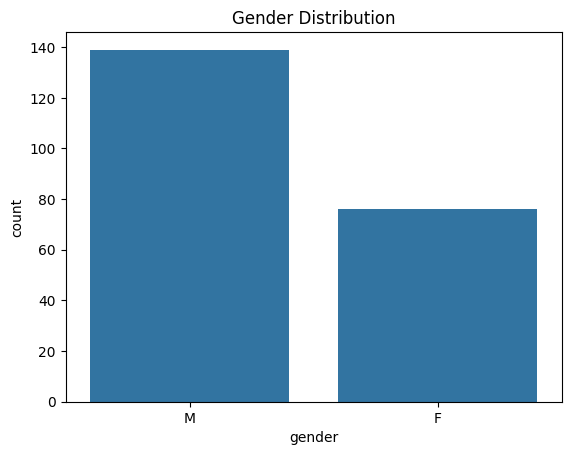

In [ ]:
print("Gender Distribution:")
print(df["gender"].value_counts(normalize=True))
sns.countplot(x=df["gender"])
plt.title("Gender Distribution")
plt.show()

### Secondary Education (10th Grade) Percentage
A histogram of `ssc_p` showing how students scored in 10th grade.

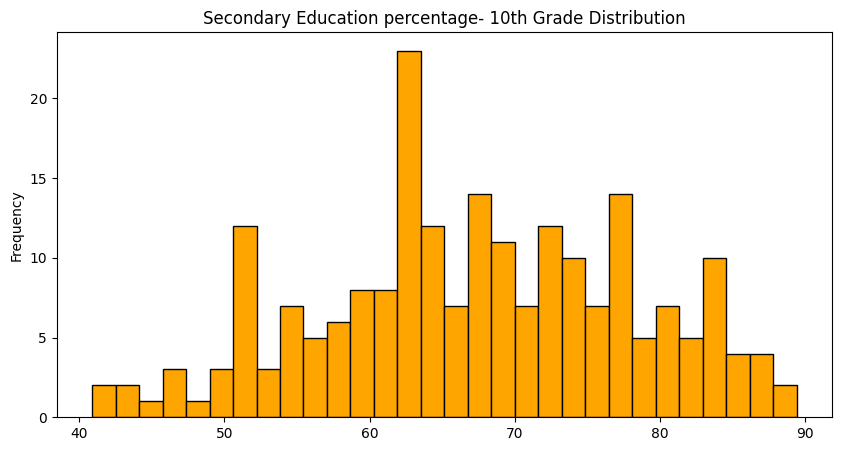

In [ ]:
# Secondary Education percentage- 10th Grade distribution
plt.figure(figsize=(10, 5))
plt.hist(df['ssc_p'].dropna(), bins=30, edgecolor='black', color='orange')
plt.title('Secondary Education percentage- 10th Grade Distribution')
plt.ylabel('Frequency')
plt.show()

### Secondary Education Board (10th Grade)
How many students studied under the **Central** board versus **Others**.

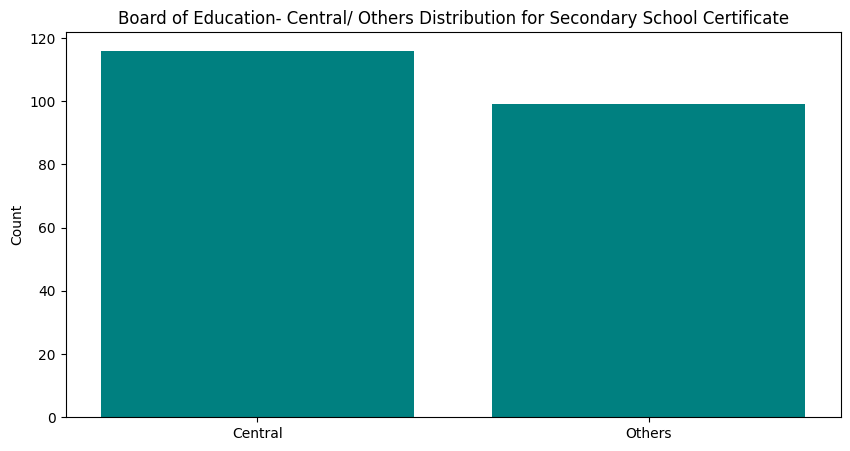

In [ ]:
ssc_b_counts = df['ssc_b'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(ssc_b_counts.index, ssc_b_counts.values, color='teal')
plt.title('Board of Education- Central/ Others Distribution for Secondary School Certificate')
plt.ylabel('Count')
plt.show()

### Higher Secondary Education (12th Grade) Percentage
A histogram of `hsc_p` showing how students scored in 12th grade.

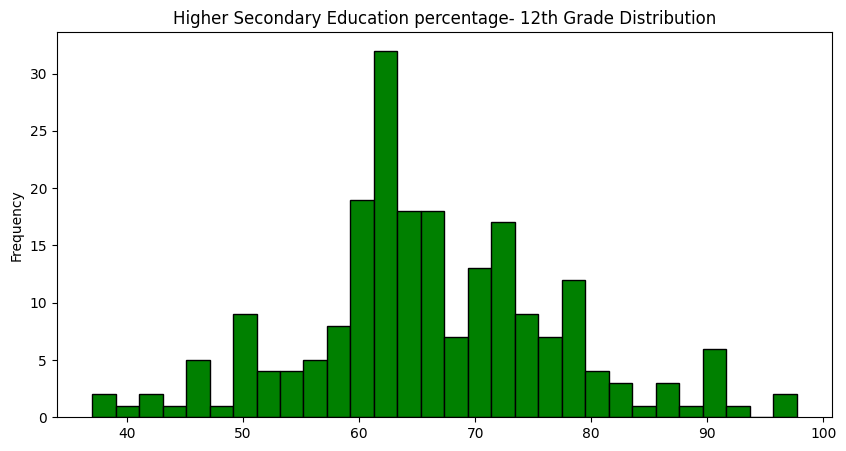

In [ ]:
# Higher Secondary Education percentage- 12th Grade distribution
plt.figure(figsize=(10, 5))
plt.hist(df['hsc_p'].dropna(), bins=30, edgecolor='black', color='green')
plt.title('Higher Secondary Education percentage- 12th Grade Distribution')
plt.ylabel('Frequency')
plt.show()

### Higher Secondary Education Board (12th Grade)
How many students studied under the **Central** board versus **Others** in 12th grade.

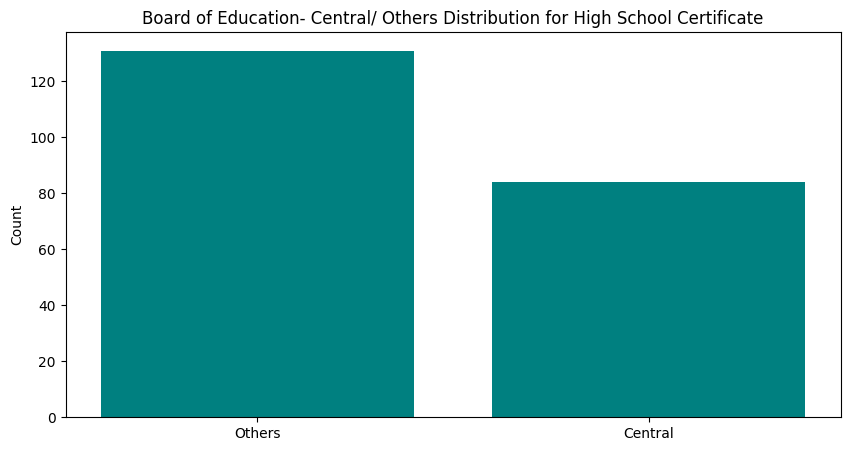

In [ ]:
hsc_b_counts = df['hsc_b'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(hsc_b_counts.index, hsc_b_counts.values, color='teal')
plt.title('Board of Education- Central/ Others Distribution for High School Certificate')
plt.ylabel('Count')
plt.show()

### Higher Secondary Specialization
How many students took **Commerce**, **Science** or **Arts** in 12th grade.

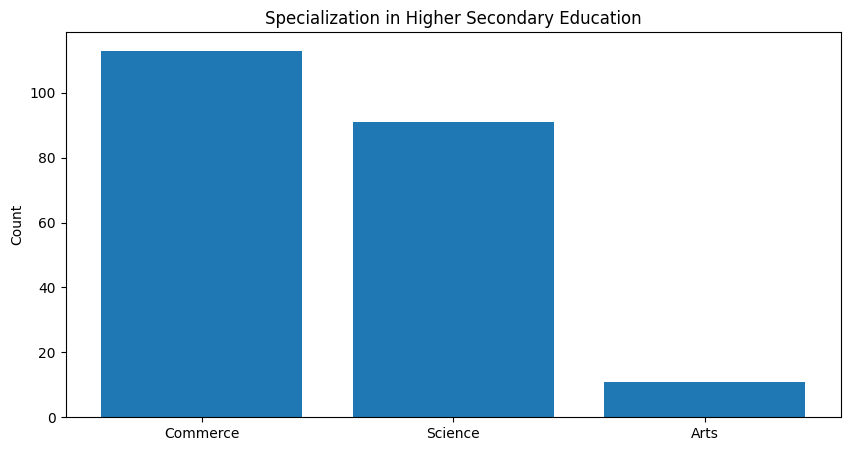

In [ ]:
hsc_s_counts = df['hsc_s'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(hsc_s_counts.index, hsc_s_counts.values)
plt.title('Specialization in Higher Secondary Education')
plt.ylabel('Count')
plt.show()

### Undergraduate Degree Percentage
A histogram of `degree_p` showing students' undergraduate scores.

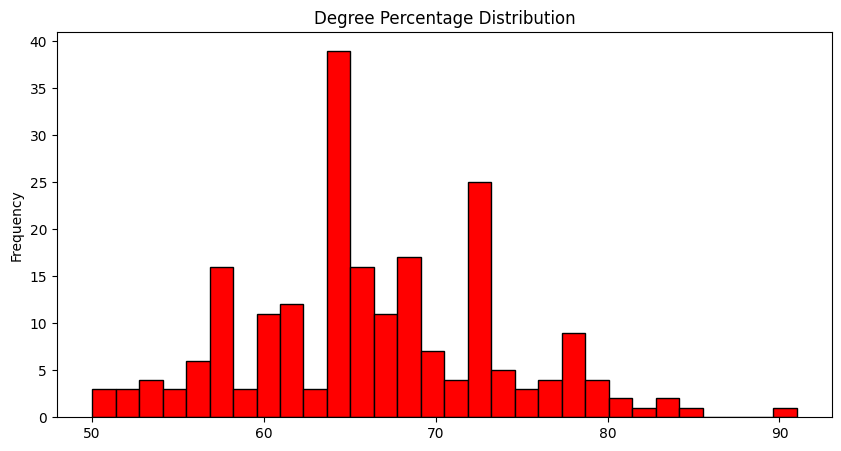

In [ ]:
# Degree Percentage distribution
plt.figure(figsize=(10, 5))
plt.hist(df['degree_p'].dropna(), bins=30, edgecolor='black', color='red')
plt.title('Degree Percentage Distribution')
plt.ylabel('Frequency')
plt.show()

### Undergraduate Degree Type
How many students studied each undergraduate field: **Comm&Mgmt**, **Sci&Tech** or **Others**.

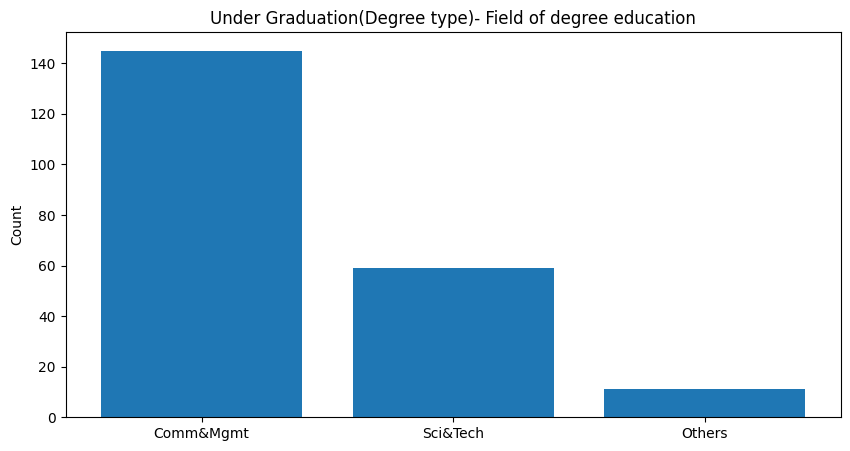

In [ ]:
degree_t_counts = df['degree_t'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(degree_t_counts.index, degree_t_counts.values)
plt.title('Under Graduation(Degree type)- Field of degree education')
plt.ylabel('Count')
plt.show()

### Work Experience
How many students have work experience and how many do not.

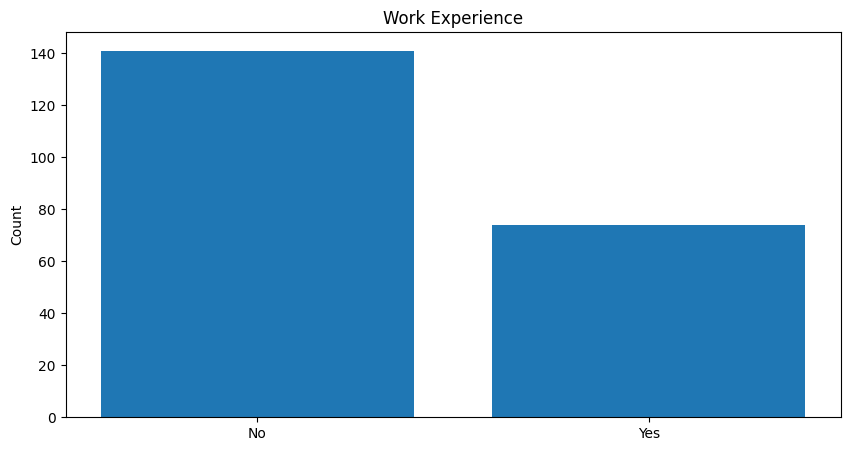

In [ ]:
workex_counts = df['workex'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(workex_counts.index, workex_counts.values)
plt.title('Work Experience')
plt.ylabel('Count')
plt.show()

### Placement Rate by Work Experience
Since `status` is 0/1, the bar height is the **placement rate**. Students with work experience are placed more often.

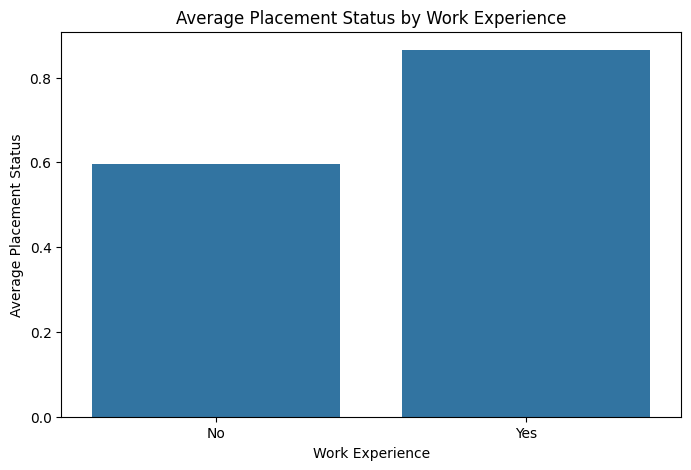

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="workex", y="status", errorbar=None)
plt.title("Average Placement Status by Work Experience")
plt.xlabel("Work Experience")
plt.ylabel("Average Placement Status")
plt.show()

### Placement Rate by Degree Type
The placement rate for each undergraduate field.

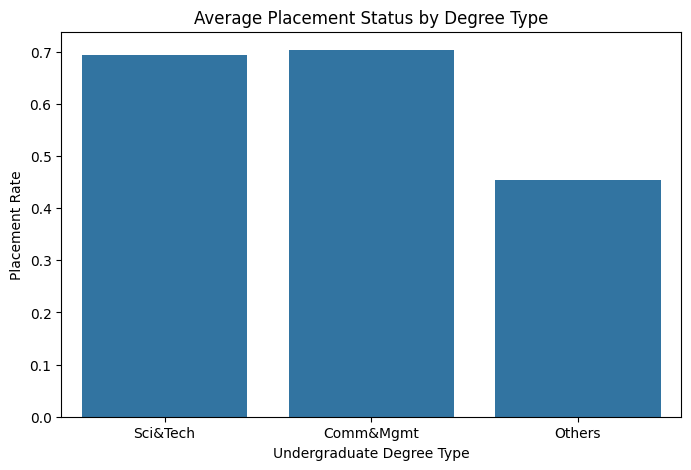

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="degree_t", y="status", errorbar=None)
plt.title("Average Placement Status by Degree Type")
plt.xlabel("Undergraduate Degree Type")
plt.ylabel("Placement Rate")
plt.show()

### Degree % vs HSC % by Placement Status
A scatter plot of degree % against 12th-grade %, coloured by placement status. Placed students mostly sit in the upper-right, where both scores are higher.

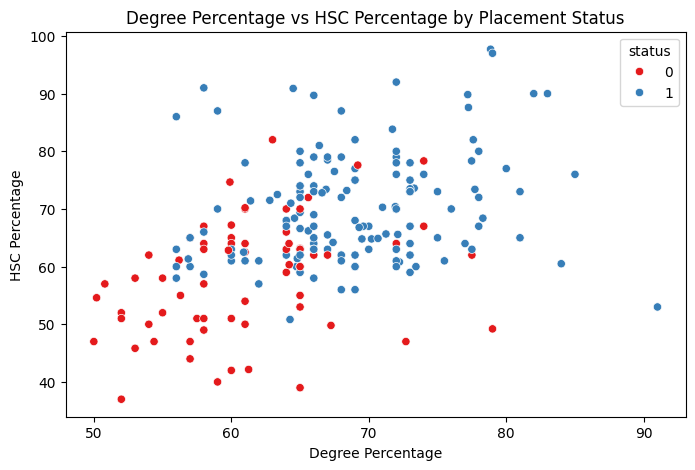

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="degree_p", y="hsc_p", hue="status", palette="Set1")
plt.title("Degree Percentage vs HSC Percentage by Placement Status")
plt.xlabel("Degree Percentage")
plt.ylabel("HSC Percentage")
plt.show()

### Employability Test Percentage
The distribution of `etest_p`, with a KDE curve showing its overall shape.

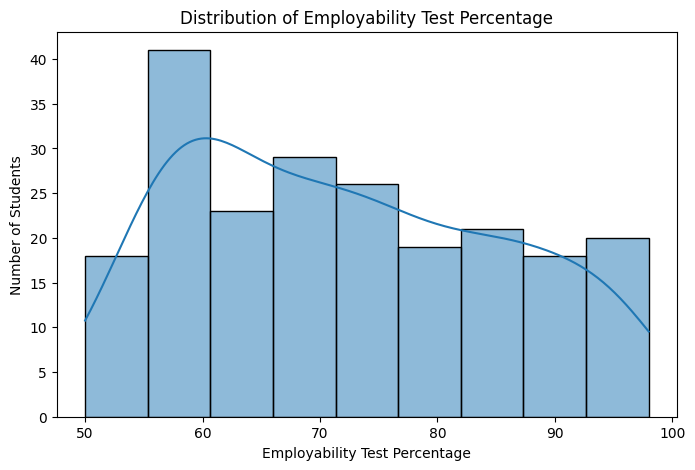

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="etest_p", kde=True)
plt.title("Distribution of Employability Test Percentage")
plt.xlabel("Employability Test Percentage")
plt.ylabel("Number of Students")
plt.show()

### MBA Specialisation
How many students chose **Mkt&Fin** and how many chose **Mkt&HR**.

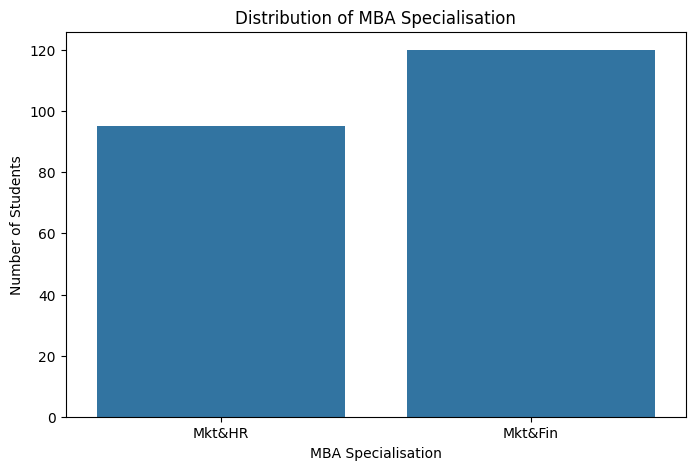

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="specialisation")
plt.title("Distribution of MBA Specialisation")
plt.xlabel("MBA Specialisation")
plt.ylabel("Number of Students")
plt.show()

### MBA Percentage
The distribution of `mba_p`, with a KDE curve.

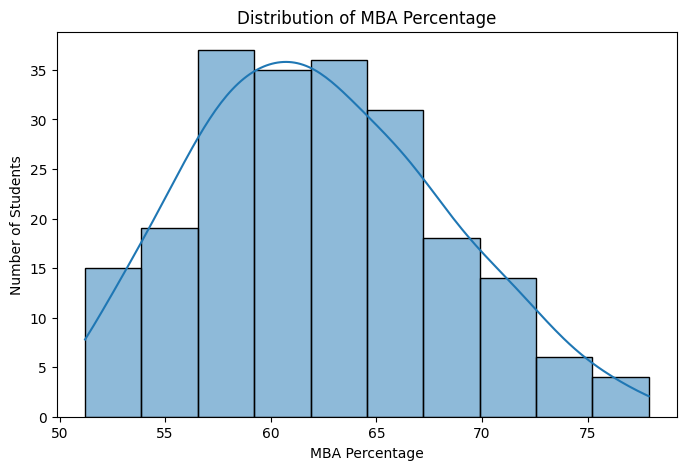

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="mba_p", kde=True)
plt.title("Distribution of MBA Percentage")
plt.xlabel("MBA Percentage")
plt.ylabel("Number of Students")
plt.show()

### Numeric Features vs Placement
Box plots of each numeric score, split by placement status. Placed students have clearly higher **ssc_p, hsc_p and degree_p**. The gap is small for `etest_p` and `mba_p`.

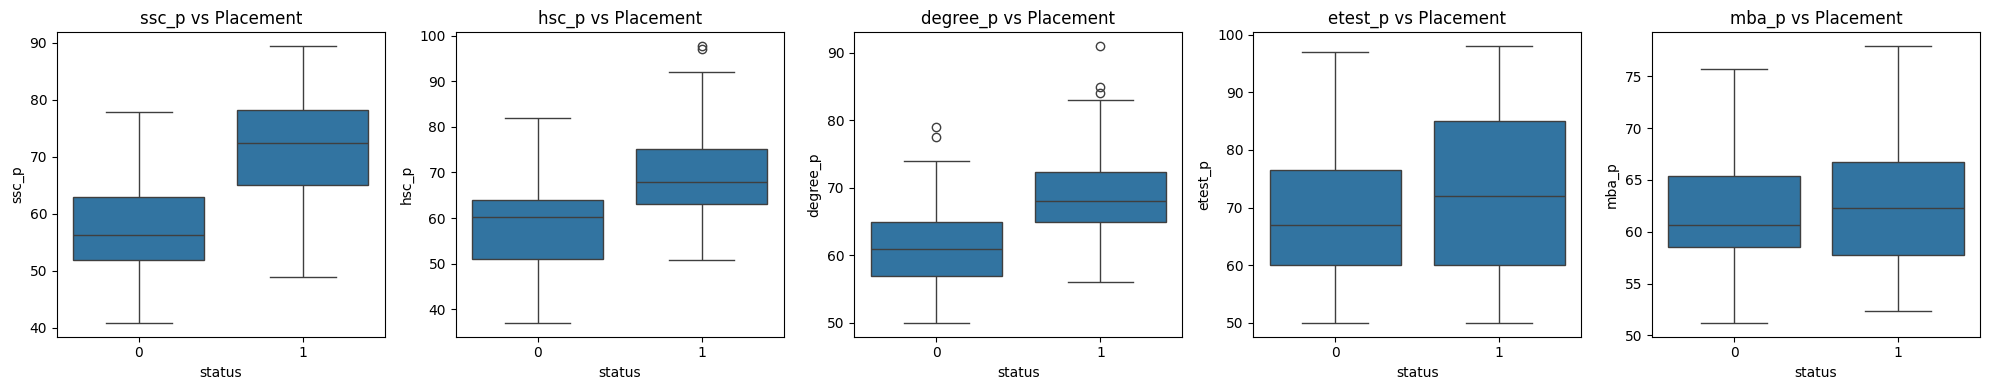

In [ ]:
num_cols = ["ssc_p", "hsc_p", "degree_p", "etest_p", "mba_p"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x="status", y=col, ax=axes[i])
    axes[i].set_title(f"{col} vs Placement")
plt.tight_layout()
plt.show()

### Placement Rate by Each Categorical Feature
The placement rate for every category of each categorical feature, in one grid. Features where the bars differ a lot (such as `workex` and `specialisation`) are likely useful predictors.

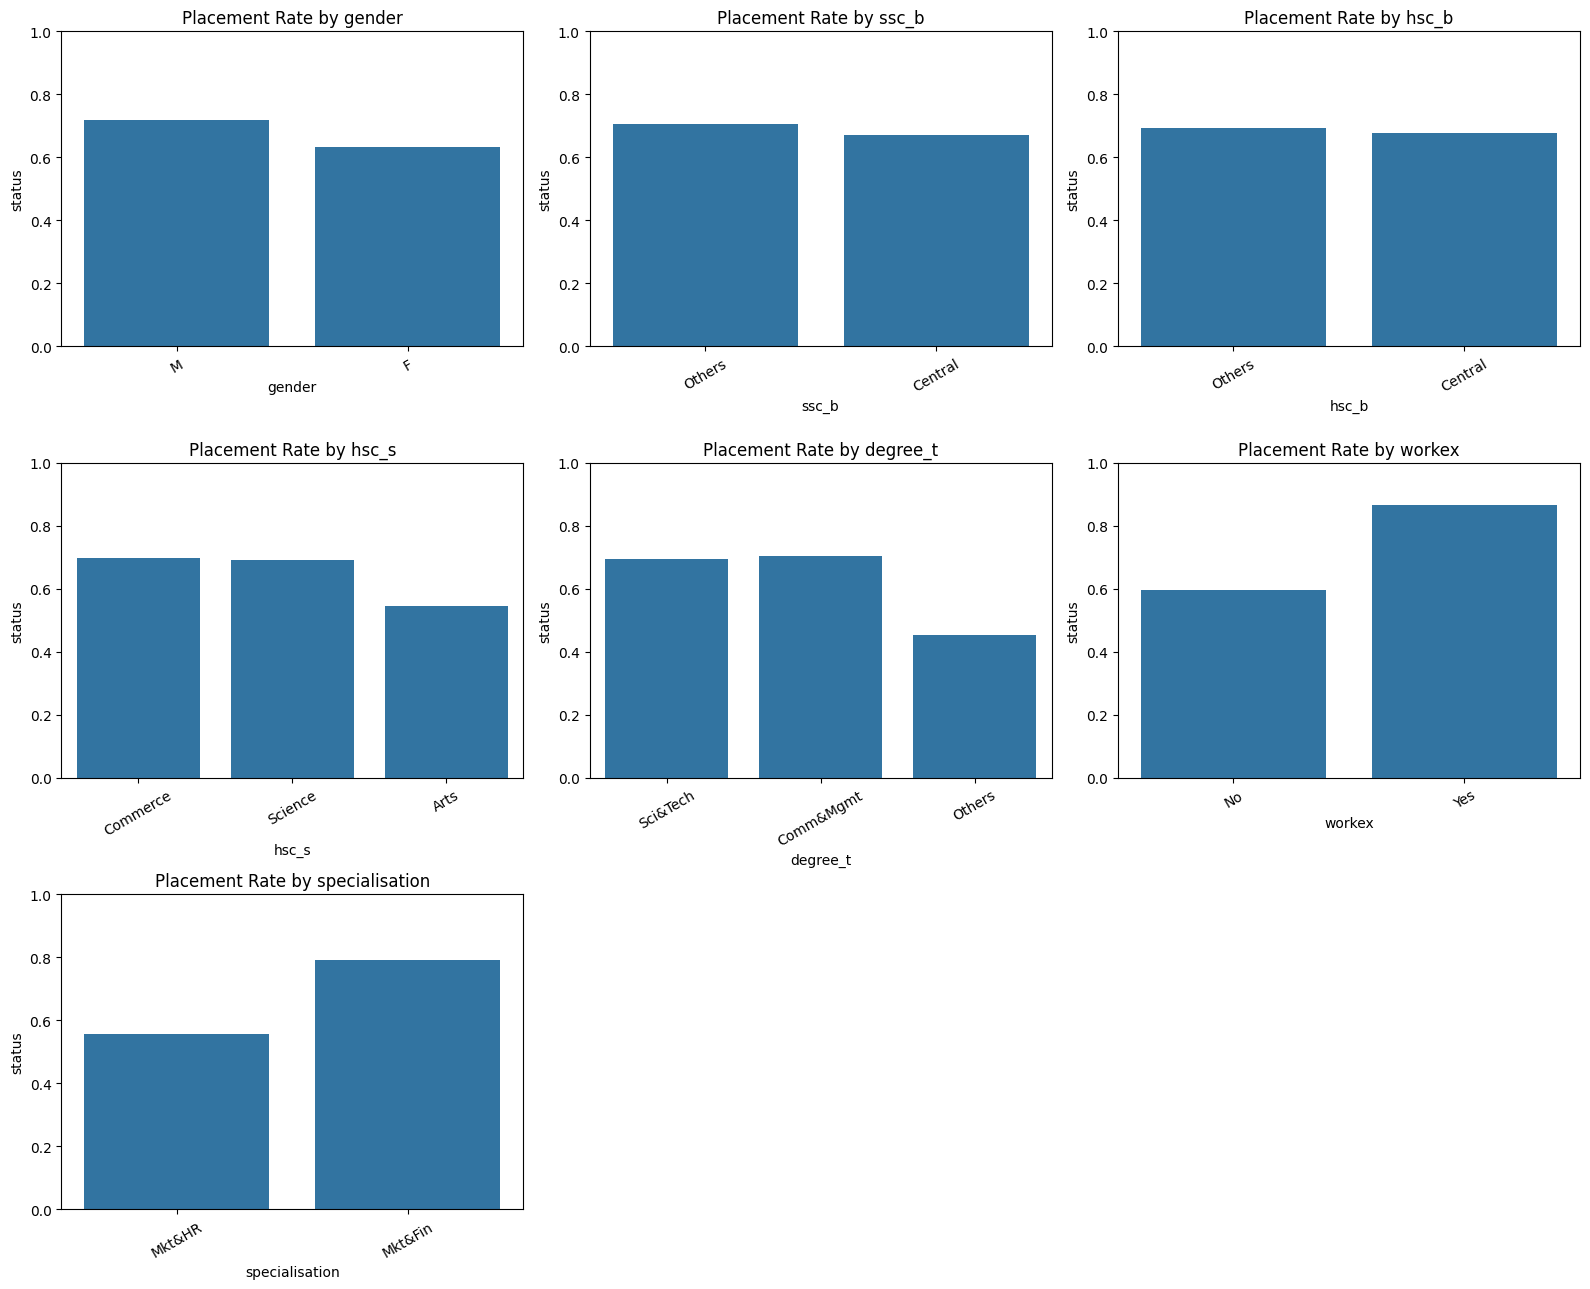

In [ ]:
cat_cols = ["gender", "ssc_b", "hsc_b", "hsc_s", "degree_t", "workex", "specialisation"]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.barplot( data=df, x=col, y="status", errorbar=None, ax=axes[i])
    axes[i].set_title(f"Placement Rate by {col}")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=30)

for j in range(len(cat_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Outlier Detection
Box plots of all numeric features side by side, to spot outliers. A few outliers appear (for example in `hsc_p`), but they are realistic scores, so we keep them.

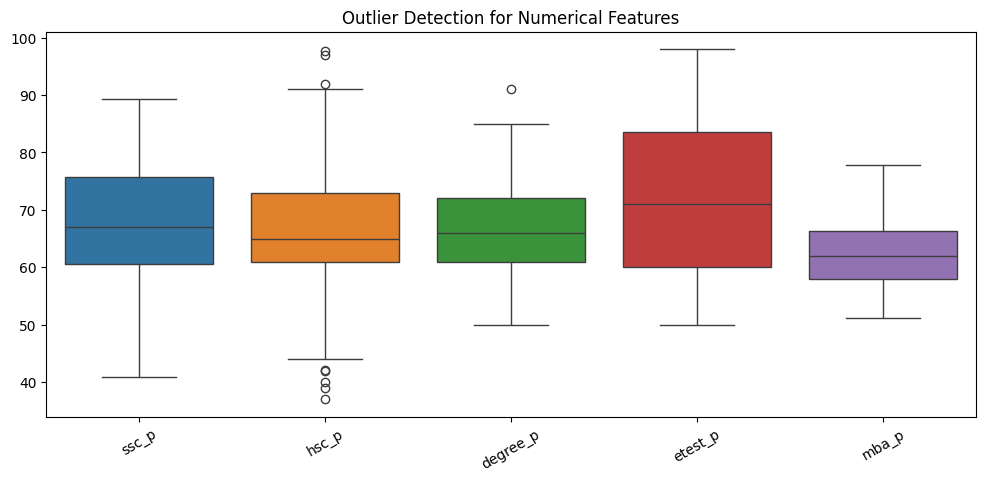

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(data=df[num_cols])

plt.title("Outlier Detection for Numerical Features")
plt.xticks(rotation=30)
plt.show()

### Correlation Heatmap
Pearson correlations between the numeric features and the target. Academic scores are moderately correlated with each other.

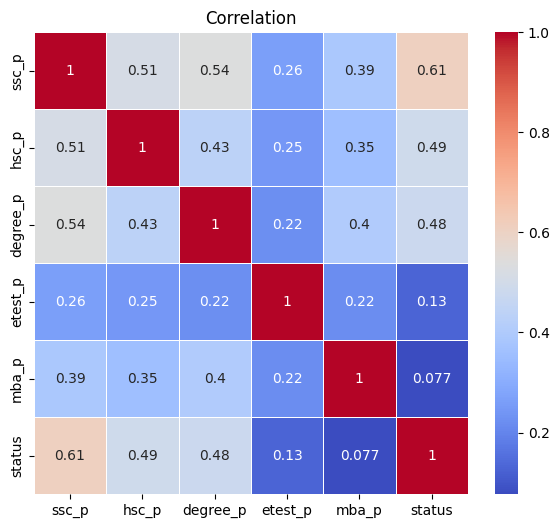

In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.5)

plt.title("Correlation")
plt.show()


### Correlation with the Target
Numeric features ranked by their correlation with `status`:
- **ssc_p (0.61)**, **hsc_p (0.49)** and **degree_p (0.48)** are the strongest.
- `etest_p` and `mba_p` are only weakly related to placement.

In [ ]:
df.corr(numeric_only=True)["status"].sort_values(ascending=False)

,status
status,1.000000
ssc_p,0.607889
hsc_p,0.491228
degree_p,0.479861
etest_p,0.127639
mba_p,0.076922


## 10. Modeling
### Separate Features and Target
`X` holds the input features and `y` holds the target (`status`).

In [ ]:
X = df.drop(columns=["status"])
y = df["status"]

### Train / Validation / Test Split
- **20%** is held out as the **test** set.
- The rest is split again, with **20%** of it used as a **validation** set (for early stopping and threshold tuning).
- `stratify` keeps the class ratio the same in each split, and `random_state` makes the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

### Preprocessing Pipeline
A `ColumnTransformer` that:
- **scales** numeric columns with `StandardScaler`
- **one-hot encodes** categorical columns with `OneHotEncoder` (`handle_unknown="ignore"` avoids errors on unseen categories)

In [ ]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns

preprocessor = ColumnTransformer([
    ("scaler", StandardScaler(), num_cols),
    ("encoder", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

### Apply Preprocessing
The preprocessor is **fit on the training set only**, then used to transform the validation and test sets. This keeps information from those sets out of training (no data leakage).

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

### Define the XGBoost Model
Key settings:
- `n_estimators=2000` is an upper limit; **early stopping** picks the actual number of trees.
- `max_depth=3`, `min_child_weight=3`, `subsample`, `colsample_bytree` and `reg_lambda` limit overfitting on this small dataset.
- `eval_metric="auc"` with `early_stopping_rounds=100` stops training when validation AUC stops improving.

In [ ]:
model = xgb.XGBClassifier(
    n_estimators=2000,           # upper bound, early stopping picks the best
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="auc",
    early_stopping_rounds=100,
    random_state=42,
    n_jobs=-1,
)

### Train the Model
We train on the training set and track AUC on the validation set. Early stopping chose **iteration 3**, so the model uses very few trees. With such a small validation set (35 rows), validation AUC is noisy and peaks early.

In [ ]:
model.fit(X_train_processed, y_train, eval_set=[(X_valid_processed, y_valid)], verbose=200)
print("Best iteration:", model.best_iteration)

[0]	validation_0-auc:0.92614
[103]	validation_0-auc:0.89394
Best iteration: 3


## 11. Evaluation
### Default Threshold (0.5)
We predict probabilities on the test set and turn them into classes using 0.5 as the cut-off.
- **AUC = 0.83**: the model ranks students fairly well.
- **Accuracy = 0.70**, but the model predicts **"Placed" for every student**: recall for class 0 is 0. Because the model has so few trees, all its probabilities stay above 0.5.

In [ ]:
proba = model.predict_proba(X_test_processed)[:, 1]
pred = (proba >= 0.5).astype(int)

print("Test AUC:", round(roc_auc_score(y_test, proba), 4))
print("Test Accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred))

Test AUC: 0.8269
Test Accuracy: 0.6977
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.70      1.00      0.82        30

    accuracy                           0.70        43
   macro avg       0.35      0.50      0.41        43
weighted avg       0.49      0.70      0.57        43



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Confusion Matrix (Threshold 0.5)
The confusion matrix confirms it: every student is predicted as **Placed**, and none of the "Not Placed" students are identified.

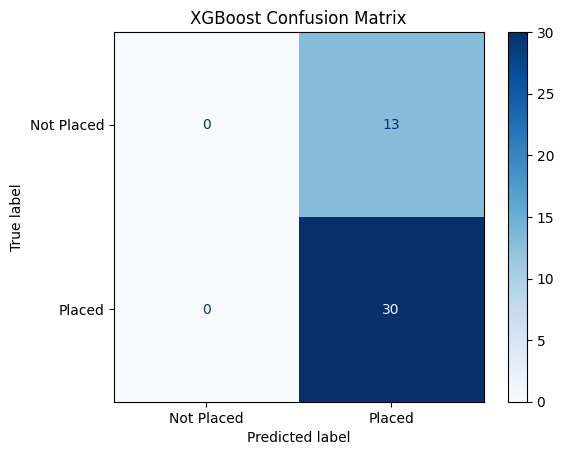

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    display_labels=["Not Placed", "Placed"],
    cmap="Blues"
)
plt.title("XGBoost Confusion Matrix")
plt.show()

### Predicted Probabilities by Actual Class
Histogram of the predicted probabilities, coloured by the true class. The red line marks the 0.5 threshold. All probabilities are above it, but "Not Placed" students tend to get lower scores, so a **higher threshold** could separate the classes.

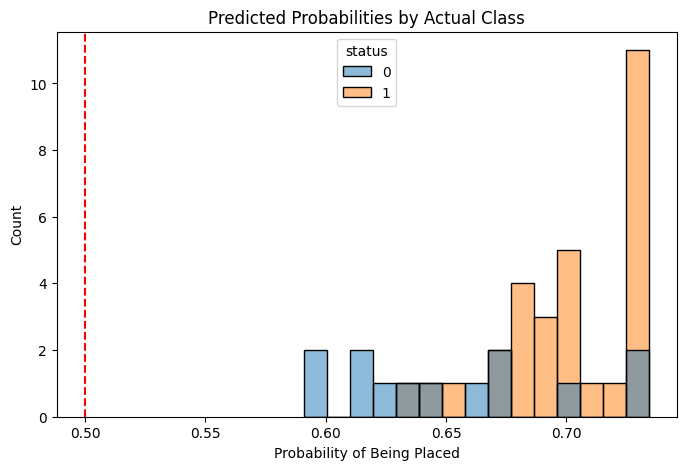

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    x=proba,
    hue=y_test,
    bins=15,
    multiple="layer"
)

plt.axvline(0.5, color="red", linestyle="--")
plt.title("Predicted Probabilities by Actual Class")
plt.xlabel("Probability of Being Placed")
plt.show()

### Threshold Tuning on the Validation Set
We try thresholds from 0.10 to 0.95 on the **validation** set (not the test set) and score each with **balanced accuracy** and **macro F1**. Both metrics treat the two classes equally. **0.70** gives the best macro F1 (0.87).

In [ ]:
valid_proba = model.predict_proba(X_valid_processed)[:, 1]

thresholds = np.arange(0.1, 0.96, 0.05)

scores = []

for t in thresholds:
    valid_pred = (valid_proba >= t).astype(int)

    scores.append({
        "threshold": round(t, 2),
        "balanced_accuracy": balanced_accuracy_score(y_valid, valid_pred),
        "macro_f1": f1_score(y_valid, valid_pred, average="macro")
    })

results = pd.DataFrame(scores)

print(results.sort_values("macro_f1", ascending=False))

    threshold  balanced_accuracy  macro_f1
12       0.70           0.892045  0.873188
11       0.65           0.776515  0.790000
10       0.60           0.545455  0.497126
0        0.10           0.500000  0.406780
1        0.15           0.500000  0.406780
2        0.20           0.500000  0.406780
6        0.40           0.500000  0.406780
3        0.25           0.500000  0.406780
4        0.30           0.500000  0.406780
5        0.35           0.500000  0.406780
9        0.55           0.500000  0.406780
8        0.50           0.500000  0.406780
7        0.45           0.500000  0.406780
13       0.75           0.500000  0.239130
14       0.80           0.500000  0.239130
15       0.85           0.500000  0.239130
16       0.90           0.500000  0.239130
17       0.95           0.500000  0.239130


### Final Evaluation with the Tuned Threshold
We apply the best threshold (**0.70**) to the test set:
- Recall for **Not Placed** rises from **0.00 to 0.77**, so the model now identifies most students at risk of not being placed.
- Macro F1 improves from **0.41 to 0.64**.
- Overall accuracy drops slightly (0.70 to 0.65), which is the expected cost of a balanced model.

Best Threshold: 0.7
              precision    recall  f1-score   support

           0       0.45      0.77      0.57        13
           1       0.86      0.60      0.71        30

    accuracy                           0.65        43
   macro avg       0.66      0.68      0.64        43
weighted avg       0.74      0.65      0.67        43



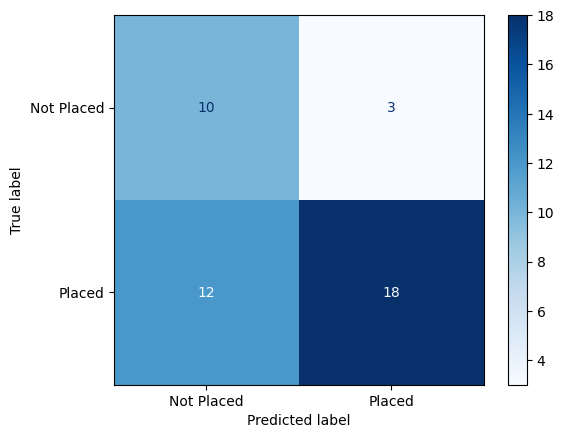

In [ ]:
best_threshold = results.loc[
    results["macro_f1"].idxmax(), "threshold"
]

pred = (proba >= best_threshold).astype(int)

print("Best Threshold:", best_threshold)
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    display_labels=["Not Placed", "Placed"],
    cmap="Blues"
)

plt.show()

![alt text](5148544.webp)